# Week 2 • Upgraded Lab 02 — Statistical evidence in a real Hubble diagram

**MSc Astrostatistics for Observational Cosmology** • 4 h practical • **Graded Lab 1 (5%)**

**Public observational source:** [Pantheon+ / SH0ES DataRelease](https://github.com/PantheonPlusSH0ES/DataRelease). All astronomical objects analysed here are genuine release entries. Bootstrap and permutation replicates are **not new observed SNe**.

**Main problem:** Is an apparent difference between low- and high-redshift supernova Hubble residuals robust to sampling uncertainty, the redshift boundary, and unusual observations? What *cannot* such a difference establish?

### Learning outcomes
- Distinguish object, measurement, statistic and sampling distribution.
- Respect the physical resampling unit (`CID`) and calibration status.
- Produce effect sizes, bootstrap intervals, empirical CDFs and a conditional permutation diagnostic.
- Identify exchangeability, unequal noise and published covariance as limitations.
- Distinguish a reference cosmology from cosmological parameter estimation.

**Required outputs:** 6 labelled plots; 1 effect-size table; 1 sensitivity table; 300–500-word conclusion. A fixed seed makes results reproducible.

## 0. Before running code: the five-line statistical statement

Write your own answer in the next Markdown cell: **estimand; observations; generative assumptions; uncertainties/dependence/selection; falsification diagnostic**. An example estimand is

$$\Delta_{\mathrm{med}}=\operatorname{median}(r\mid z\ge z_*)-\operatorname{median}(r\mid z<z_*).$$

This is a **descriptive effect**, not a fitted value of $H_0$ or $\Omega_m$.

**Student response (complete before observing results):**

- **Estimand**: difference between the median Hubble residuals of low and high redshift of supernovae. 
- **Observed data**:We have the redshift, the distance modulus, and the uncertainties. 
- **Assumptions**: We assume that the supernova distances can be compared with a reference cosmological model.
- **Dependence/selection**: Measurement uncertainties, repeated observatiins and selection biases may affect our results. 
- **Diagnostic**: We use bootstrap and permutation to check the uncertainty and the difference between the two groups. 


In [1]:
# Run once. The public source must be reachable by Colab; no invented fallback observations.
import sys, io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import stats
from scipy.integrate import cumulative_trapezoid

SEED = 2026
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.18})
print('Python', sys.version.split()[0], '| NumPy', np.__version__, '| SciPy', __import__('scipy').__version__)

Python 3.14.6 | NumPy 2.4.6 | SciPy 1.18.0


## 1. Download and audit the released Pantheon+ data

The file includes **light-curve measurements**, not necessarily one independent row per physical SN. Inspect `CID` before resampling. We use `MU_SH0ES` only as a pre-calibrated, descriptive distance-modulus product; its absolute calibration means it cannot be used here as an independent $H_0$ measurement.

For a careful reference comparison, distinguish the Hubble-diagram redshift $z_{\rm HD}$ (integral) from heliocentric $z_{\rm HEL}$ (luminosity-distance prefactor).

In [2]:
BASE = ('https://raw.githubusercontent.com/PantheonPlusSH0ES/DataRelease/'
        'main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR/')
TABLE_URL = BASE + 'Pantheon%2BSH0ES.dat'
CACHE = Path('data_cache/pantheon_plus')
CACHE.mkdir(parents=True, exist_ok=True)
table_path = CACHE / 'Pantheon+SH0ES.dat'
if not table_path.exists():
    resp = requests.get(TABLE_URL, timeout=120)
    resp.raise_for_status()
    table_path.write_bytes(resp.content)
sn = pd.read_csv(table_path, sep=r'\s+')
required = {'CID', 'zHD', 'zHEL', 'MU_SH0ES', 'MU_SH0ES_ERR_DIAG', 'IS_CALIBRATOR'}
missing = required - set(sn.columns)
assert not missing, f'Missing Pantheon+ columns: {missing}'
print('Release measurement rows:', len(sn), '| Unique physical CID:', sn.CID.nunique())
print('Duplicate CID measurement rows:', len(sn)-sn.CID.nunique())
display(sn[list(required)].head())

Release measurement rows: 1701 | Unique physical CID: 1543
Duplicate CID measurement rows: 158


,zHD,IS_CALIBRATOR,MU_SH0ES_ERR_DIAG,CID,zHEL,MU_SH0ES
0,0.00122,1,1.516450,2011fe,0.00082,28.9987
1,0.00122,1,1.517470,2011fe,0.00082,29.0559
2,0.00256,1,0.782372,2012cg,0.00144,30.7233
3,0.00256,1,0.799068,2012cg,0.00144,30.7449
4,0.00299,0,0.881212,1994DRichmond,0.00187,30.7757


### Discussion A — what is the statistical unit?

A bootstrap that resamples rows can repeatedly include the same physical SN with different observation identifiers. If the intended sampling unit is a physical SN, that can exaggerate the effective sample size. **For exploratory descriptions only**, aggregate repeated rows by `CID` using medians. This is *not* the released cosmological likelihood and does not preserve the full covariance.

In [3]:
obs = (sn[['CID', 'zHD', 'zHEL', 'MU_SH0ES', 'MU_SH0ES_ERR_DIAG', 'IS_CALIBRATOR']]
       .replace([np.inf, -np.inf], np.nan)
       .dropna(subset=['CID','zHD','zHEL','MU_SH0ES'])
       .groupby('CID', as_index=False)
       .agg(zHD=('zHD','median'), zHEL=('zHEL','median'),
            MU_SH0ES=('MU_SH0ES','median'),
            MU_ERR_DIAG=('MU_SH0ES_ERR_DIAG','median'),
            IS_CALIBRATOR=('IS_CALIBRATOR','max')))
obs = obs.loc[(obs.zHD > 0.01) & (obs.IS_CALIBRATOR == 0) &
              (obs.zHEL > 0)].copy().reset_index(drop=True)
assert len(obs)>100, 'Unexpectedly small real-data selection; inspect release/filters.'
print('Exploratory Hubble-flow objects:', len(obs))
print('z range:', obs.zHD.min(), obs.zHD.max())

Exploratory Hubble-flow objects: 1466
z range: 0.01016 2.26137


## 2. Define a reference, not a fit

Under spatially flat $\Lambda$CDM (neglecting radiation in this redshift range),

$$E(z)=\sqrt{\Omega_m(1+z)^3+1-\Omega_m},\qquad
D_L=\frac{c}{H_0}(1+z_{\rm HEL})\int_0^{z_{\rm HD}}\!\frac{dz'}{E(z')}.$$

$$\mu_{\rm ref}=5\log_{10}[D_L/\mathrm{Mpc}]+25,\qquad
r_i=\mu_{\rm SH0ES,i}-\mu_{\rm ref,i}.$$

Set $H_0^{\rm ref}=73\,\mathrm{km\ s^{-1}\ Mpc^{-1}}$ and $\Omega_m^{\rm ref}=0.3$. These are **chosen plotting values**, not inferences.

In [4]:
C_KMS = 299792.458

def mu_flat(z_hd, z_hel, omega_m=0.30, H0=73.0, n_grid=8192):
    """Flat-LCDM SN distance modulus: zHD in integral, zHEL in prefactor."""
    z_hd = np.asarray(z_hd, float)
    z_hel = np.asarray(z_hel, float)
    assert z_hd.shape == z_hel.shape
    assert np.all(z_hd>0) and np.all(z_hel>0)
    assert 0.0 <= omega_m <= 1.0 and H0>0
    grid = np.linspace(0, max(float(np.max(z_hd))*1.002, .02), n_grid)
    ez = np.sqrt(omega_m*(1+grid)**3 + (1-omega_m))
    integral = cumulative_trapezoid(1/ez, grid, initial=0.)
    dc = C_KMS/H0 * np.interp(z_hd, grid, integral)
    dl = (1+z_hel)*dc
    return 5*np.log10(dl)+25

H0_REF, OM_REF = 73., .30
obs['MU_REF'] = mu_flat(obs.zHD, obs.zHEL, OM_REF, H0_REF)
obs['RESID'] = obs.MU_SH0ES-obs.MU_REF
print('Median reference residual [mag]:', round(obs.RESID.median(), 4))
assert np.isfinite(obs.RESID).all()

Median reference residual [mag]: -0.0159


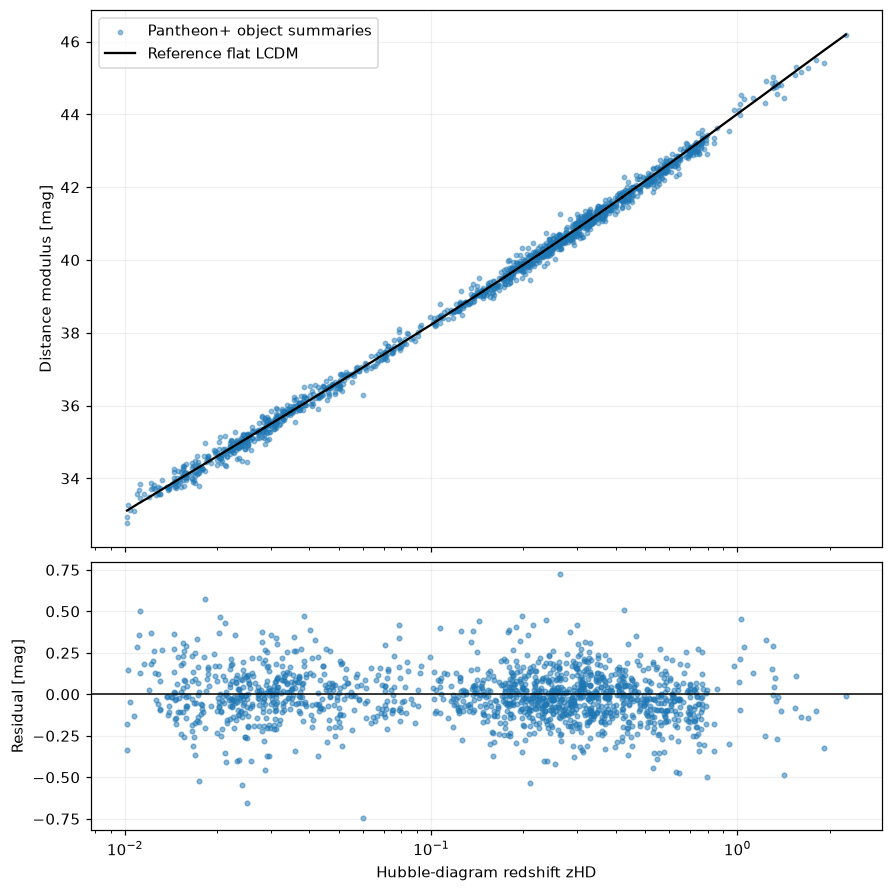

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True,
                                     gridspec_kw={'height_ratios':[2,1]}, constrained_layout=True)
ix = np.argsort(obs.zHD.to_numpy())
ax1.scatter(obs.zHD, obs.MU_SH0ES, s=8, alpha=.45, label='Pantheon+ object summaries')
ax1.plot(obs.zHD.to_numpy()[ix], obs.MU_REF.to_numpy()[ix], color='black', lw=1.5, label='Reference flat LCDM')
ax1.set_ylabel('Distance modulus [mag]'); ax1.legend()
ax2.scatter(obs.zHD, obs.RESID, s=9, alpha=.5)
ax2.axhline(0, color='black', lw=1)
ax2.set(xlabel='Hubble-diagram redshift zHD', ylabel='Residual [mag]', xscale='log')
ax1.set_xscale('log')
plt.show()

**Question 1:** Identify two observational effects besides cosmological evolution that could create apparent redshift-dependent residual structure. Explain why the reference model and SH0ES zero-point choice matter.

Selection biases and calibration errors create differences un the residuals at different redshifts. The reference model matters because residuals depend on the predicted distances. Also, the SH0ES zero-point matters becuase it sets the distance scale and can shift the results. 

## 3. Sampling distribution and bootstrap of the median

For $N$ independent, identically sampled *objects*, a nonparametric bootstrap draws $N$ object indices **with replacement** and recomputes an estimator. The resulting distribution approximates resampling uncertainty **conditional on the observed sample and its sampling assumptions**. It does not reproduce survey-selection uncertainty, common calibration errors, or inter-SN covariance. With small or strongly structured samples, ordinary percentile intervals may have inadequate coverage.

Observed median: -0.0159257590234958  | Bootstrap 95% percentile CI: [-0.02308057 -0.00787944]


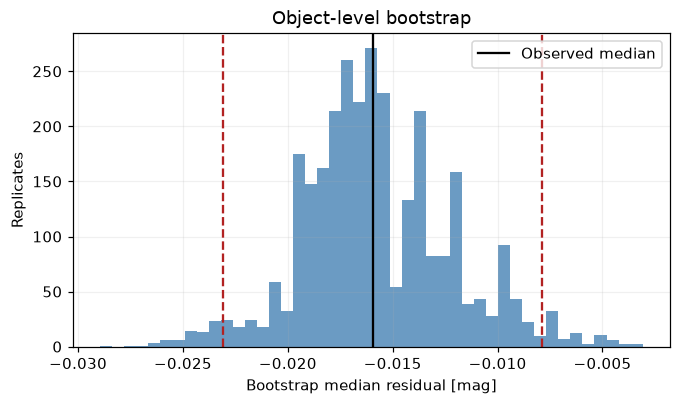

In [6]:
def bootstrap_stat(x, statistic=np.median, n_boot=2500, seed=2026):
    x = np.asarray(x, float)
    assert np.all(np.isfinite(x)) and x.size>1
    local = np.random.default_rng(seed)
    out = np.empty(n_boot)
    for k in range(n_boot):
        out[k] = statistic(local.choice(x, size=x.size, replace=True))
    return out

values = obs.RESID.to_numpy()
boot_med = bootstrap_stat(values, n_boot=3000)
ci_global = np.quantile(boot_med, [.025, .5, .975])
print('Observed median:', np.median(values), ' | Bootstrap 95% percentile CI:', ci_global[[0,2]])
fig, ax = plt.subplots(figsize=(7,3.7))
ax.hist(boot_med, bins=45, color='steelblue', alpha=.8)
ax.axvline(np.median(values), color='black', label='Observed median')
for q in [ci_global[0], ci_global[2]]: ax.axvline(q, ls='--', color='firebrick')
ax.set(xlabel='Bootstrap median residual [mag]', ylabel='Replicates', title='Object-level bootstrap')
ax.legend(); plt.show()

**Question 2:** Which uncertainty components are reflected in this interval, and which are missing? Would a narrow interval prove cosmological-model accuracy?

The interval shows the sampling uncertainty of the median residual and we god from −0.02308 to −0.00788 magnitudes. This is not including the calibration erros or selection effects. A narrow interval means our median is estimated precisely, but doesnt prove that the model is correct.

## 4. Define a prespecified low/high-redshift contrast

Set $z_*=0.30$ **before** inspecting its statistical significance. The estimand is

$$\Delta_{\mathrm{med}}=\mathrm{median}(r_{\mathrm{high}})-\mathrm{median}(r_{\mathrm{low}}).$$

The redshift groups need not have identical scatter or selection functions. A signed effect and interval are more informative than a p-value alone.

N low=972, N high=494
Delta median=-0.0087 mag, conditional bootstrap 95% CI = (-0.0233, +0.0039)


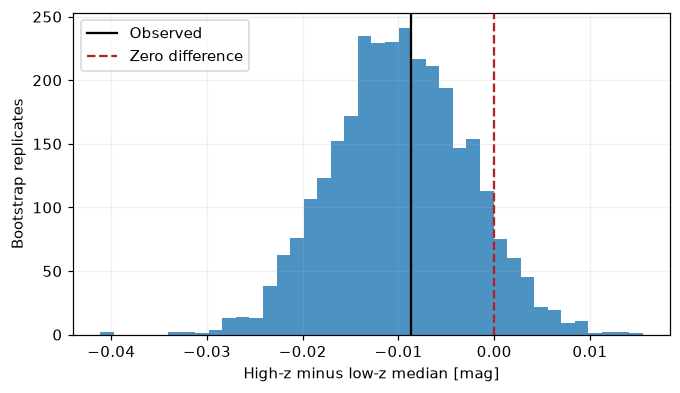

In [7]:
Z_SPLIT = .30

def groups_at(split, frame=obs):
    lo = frame.loc[frame.zHD < split, 'RESID'].to_numpy(float)
    hi = frame.loc[frame.zHD >= split, 'RESID'].to_numpy(float)
    if min(len(lo),len(hi)) < 20: raise ValueError('Insufficient objects in one group.')
    return lo, hi

def delta_median(lo,hi): return float(np.median(hi)-np.median(lo))

def boot_group_delta(lo,hi,n_boot=3000,seed=2026):
    local = np.random.default_rng(seed)
    result=np.empty(n_boot)
    for k in range(n_boot):
        a=local.choice(lo,len(lo),replace=True)
        b=local.choice(hi,len(hi),replace=True)
        result[k]=delta_median(a,b)
    return result

low, high = groups_at(Z_SPLIT)
delta_obs = delta_median(low, high)
boot_delta = boot_group_delta(low,high)
ci_delta=np.quantile(boot_delta,[.025,.975])
print(f'N low={len(low)}, N high={len(high)}')
print(f'Delta median={delta_obs:+.4f} mag, conditional bootstrap 95% CI = ({ci_delta[0]:+.4f}, {ci_delta[1]:+.4f})')
fig,ax=plt.subplots(figsize=(7,3.8))
ax.hist(boot_delta, bins=40, alpha=.8)
ax.axvline(delta_obs,color='black', label='Observed')
ax.axvline(0,color='firebrick',ls='--', label='Zero difference')
ax.set(xlabel='High-z minus low-z median [mag]',ylabel='Bootstrap replicates')
ax.legend();plt.show()

## 5. Permutation testing: useful **only if exchangeability is plausible**

We test a *stronger null* than equal medians: under the test null, low/high labels are exchangeable for the residual measurements. With unequal redshift-dependent errors, selection, or survey composition, this is generally questionable; the resulting p-value is therefore a **conditional diagnostic**, *not* a formal claim about evolution or cosmology.

For $B$ shuffled samples,
$$p_{\mathrm{MC}}=\frac{1+\#\{T_b\ge T_{\rm obs}\}}{B+1}, \quad T=|\Delta_{\rm med}|.$$

**Think before running:** How would unequal group variances invalidate the exchangeability argument?

If two groups have different variances, the residuals have different distributions. So we cannot freely exchange observations between the stablished groups, so the permutation test that may give an unreliable value. 

* Variance: Measures how spread out the residuals are.
* Exchangeability: Means we can swap observations between the low- and high-redshift groups without changing their statistical distribution under the null hypothesis.

Conditional-exchangeability p-value: 0.245 (not a cosmological model test)


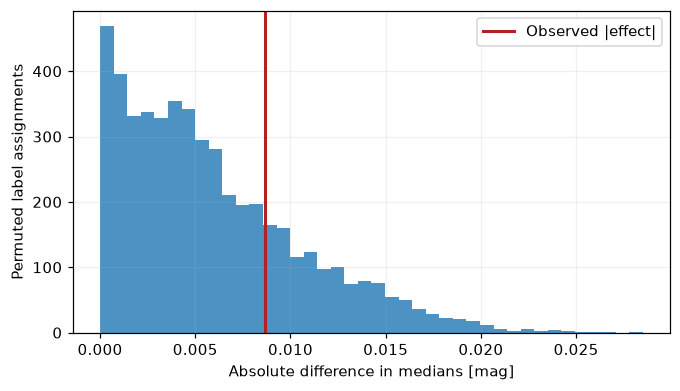

In [8]:
def conditional_permutation(lo,hi,n_perm=5000,seed=2026):
    local=np.random.default_rng(seed)
    pool=np.r_[lo,hi]
    n=len(lo)
    observed=abs(delta_median(lo,hi))
    null=np.empty(n_perm)
    for b in range(n_perm):
        perm=local.permutation(pool)
        null[b]=abs(delta_median(perm[:n],perm[n:]))
    p=(1+np.count_nonzero(null>=observed))/(1+n_perm)
    return observed,p,null

T_obs, p_cond, null=conditional_permutation(low, high)
print(f'Conditional-exchangeability p-value: {p_cond:.4g} (not a cosmological model test)')
fig,ax=plt.subplots(figsize=(7,3.8))
ax.hist(null,bins=40,alpha=.8)
ax.axvline(T_obs,color='firebrick',lw=2,label='Observed |effect|')
ax.set(xlabel='Absolute difference in medians [mag]',ylabel='Permuted label assignments')
ax.legend();plt.show()

### Sampling distributions differ by redshift

Plot group histograms and their ECDFs. A visible difference in width or tails is evidence **against** naive exchangeability and a reason to avoid treating the conditional permutation p-value as a definitive inferential result.

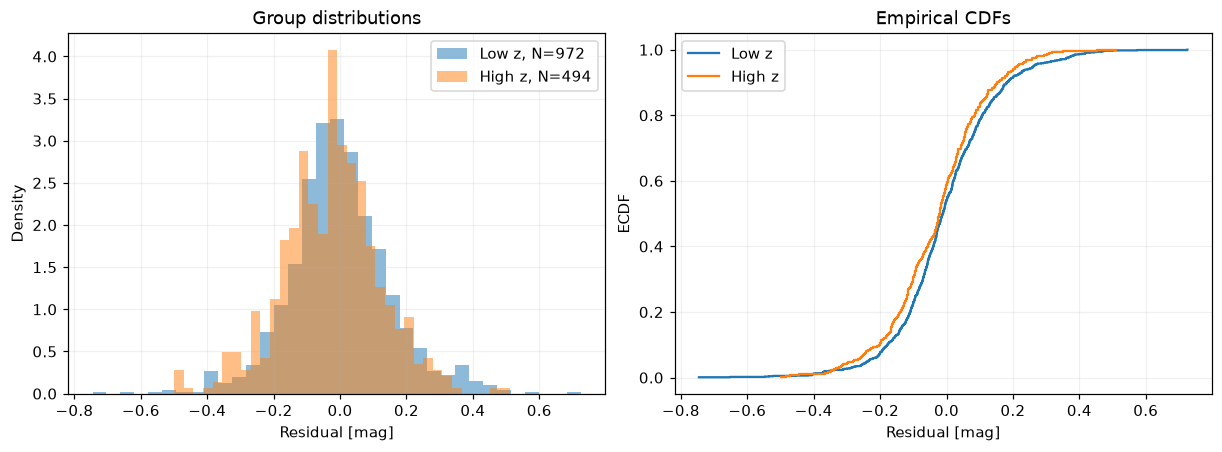

Group std devs: 0.15625102801471463 0.14733481173069532


In [9]:
def ecdf(x):
    xs=np.sort(np.asarray(x,float)); return xs, np.arange(1,len(xs)+1)/len(xs)
fig,(ax0,ax1)=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for arr,lab in [(low,'Low z'),(high,'High z')]:
    ax0.hist(arr,bins=35,alpha=.50,density=True,label=f'{lab}, N={len(arr)}')
    x,y=ecdf(arr); ax1.step(x,y,where='post',label=lab)
ax0.set(xlabel='Residual [mag]',ylabel='Density',title='Group distributions')
ax1.set(xlabel='Residual [mag]',ylabel='ECDF',title='Empirical CDFs')
ax0.legend();ax1.legend();plt.show()
print('Group std devs:', np.std(low,ddof=1), np.std(high,ddof=1))

The two groups have slightly different distributions.
- First, the standard deviation are  0.1563 and 0.1473. These differences could be from observational effects. .

A small p-value suggests that the observed difference is unusual under the assumptions of the statistical test. It doesn’t explain what caused that difference.

**Question 3:** Explain why the statement “p is small, therefore the Universe evolves differently” would be invalid. What would a full correlated-covariance and selection-aware model require?

A small p value does not necessarily mean that things evolves differently, a reason why we could have differences is by observational effects. A more complete model would need to include the unvertainties, the correlations, calibration errorsn before making conclusions or errors in the model. 

## 6. Robust summaries and a sensitivity exercise

Use $\mathrm{MAD}=\mathrm{median}(|r_i-\mathrm{median}(r)|)$, and distinguish it from $1.4826\times\mathrm{MAD}$ (a Gaussian-consistent scale estimate).

Reassess the **effect size and its interval only** at nearby prespecified boundaries $0.25$ and $0.35$. Do not scan many boundaries to select the smallest p-value.

In [10]:
def summary(x):
    x=np.asarray(x,float)
    return dict(N=len(x),mean=np.mean(x),std=np.std(x,ddof=1),
                median=np.median(x),MAD=np.median(np.abs(x-np.median(x))))
summary_table=pd.DataFrame({'All':summary(values),'Low z':summary(low),'High z':summary(high)}).T
print('Robust versus classical summary');display(summary_table.round(5))
rows=[]
for split in [.25,.30,.35]:
    a,b=groups_at(split)
    interval=np.quantile(boot_group_delta(a,b, n_boot=2500, seed=2026),[.025,.975])
    rows.append(dict(z_split=split,N_low=len(a),N_high=len(b),
                     delta_median=delta_median(a,b),ci_low=interval[0],ci_high=interval[1]))
sensitivity=pd.DataFrame(rows)
print('Prespecified boundary sensitivity');display(sensitivity.round(5))

Robust versus classical summary


,N,mean,std,median,MAD
All,1466.0,-0.01087,0.15376,-0.01593,0.08745
Low z,972.0,-0.00201,0.15625,-0.01181,0.08822
High z,494.0,-0.02832,0.14733,-0.02047,0.08933


Prespecified boundary sensitivity


,z_split,N_low,N_high,delta_median,ci_low,ci_high
0,0.25,852,614,-0.01528,-0.02666,-0.00117
1,0.30,972,494,-0.00866,-0.02314,0.00411
2,0.35,1093,373,-0.02079,-0.04240,-0.00866


## 7. Influence diagnostic

Identify the five largest $|r_i|$ and compute the effect with/without them. **This is a sensitivity diagnostic, not a license to remove inconvenient observations.**

In [11]:
extremes=obs.loc[obs.RESID.abs().nlargest(5).index,['CID','zHD','RESID']]
display(extremes)
reduced=obs.drop(index=extremes.index)
lo2,hi2=groups_at(Z_SPLIT, reduced)
influence=pd.DataFrame([
    {'sample':'All objects','N':len(obs),'median_resid':np.median(values),'delta_med':delta_obs},
    {'sample':'Exclude 5 |r| extremes','N':len(reduced),'median_resid':reduced.RESID.median(),'delta_med':delta_median(lo2,hi2)}
])
display(influence)

,CID,zHD,RESID
1362,LSQ13crf,0.05974,-0.745503
499,13956,0.26303,0.725410
963,2011dn,0.02513,-0.651965
948,2010ai,0.01826,0.573888
954,2010gp,0.02411,-0.547575


,sample,N,median_resid,delta_med
0,All objects,1466,-0.015926,-0.008659
1,Exclude 5 |r| extremes,1461,-0.015908,-0.008813


## 8. Failure tests (run and interpret)

**Counterfactual A:** Change reference $H_0$ from 73 to 70. The *absolute* residual zero point shifts, while the low-minus-high contrast should barely respond to a uniform zero-point shift. Verify numerically.

**Counterfactual B:** Shuffle the *object IDs*, rather than the physical redshifts, and ask whether that constructs a valid astronomical experiment (it does not).

**Counterfactual C:** Explain the difference between drawing bootstrap replicates and adding new cosmological observations.

In [12]:
shifted=obs.MU_SH0ES.to_numpy()-mu_flat(obs.zHD,obs.zHEL,.30,70.)
diff_shifted = np.median(shifted[obs.zHD>=Z_SPLIT])-np.median(shifted[obs.zHD<Z_SPLIT])
expected_constant = 5*np.log10(70./73.)
print('Median residual shift (reference H0 73 -> 70):',np.median(shifted-values))
print('Theoretical uniform shift:', expected_constant)
print('Difference in redshift contrast:',diff_shifted-delta_obs)
assert np.allclose(shifted-values, expected_constant, atol=3e-4)
assert np.allclose(diff_shifted, delta_obs, atol=3e-4)

Median residual shift (reference H0 73 -> 70): -0.09112410053099751
Theoretical uniform shift: -0.09112410053099547
Difference in redshift contrast: 0.0


Changing the reference H0 from 73 to 70 shifts the median residual by approximately −0.09112 mag, which agrees with the theoretical value. 
But the difference between the low and high redshift groups remains the same. 

If we change the ID it does not reperesent a valid experiment because the identifiers dont change the phyisical properties of the supernova. 

Bootrstrap samples are created from existing observations. They do not represent new observations or provide any additional data. 

# Extended analysis • submit the same notebook (graded 5%)

**E1. Scientific inference (20%)State your observational and sampling model explicitly.**
 We use Pantheon+, a dataset to compate the observed distance moduli of supernova Type Ia with a reference cosmological model. We calculate the residuals as the difference between observed values and predicted values. 
 
For our analysis, we treat each supernova as one object and we use bootstrap resampling to estimate the uncertainty. In reality, measurement arent always independent, becuase we have to consider measurement errors and calibration errors, which affect our results.  

**E2. Uncertainty (25%) Report the high-minus-low median with a 95% conditional bootstrap interval, and explain which noise/dependence components are excluded.**

From our results, we found that the difference between low and high redshifts is -0.0087, with a 95% bootstrap interval of [−0.0233, 0.0039].The interval includes zero, so the results are compatible with no difference between the two groups. It is important to mention that the bootstrap only estimates sampling uncertainty using existing data. It doesnt account for measurement errores, calibrations, correlations or selection effects. 

**E3. Test validity (20%) Evaluate whether label exchangeability is credible and name a safer alternative to infer a redshift trend (e.g., a heteroscedastic regression model with the published covariance and survey/selection terms).**

The low- and high-redshift groups have different standard deviations. Low redshift: 0.1563 mag and High redshift: 0.1473 mag. Even that the difference is small, it suggests that the group might not have identical distributions. So exchanging the labels might not be completely valid. 

Therefore, the permutation test results should be interpreted carefully. A better alternative would be a heteroscedastic regression model that takes on account for different measurement uncertainties, correlations between supernovae, and survey selection effects.

**E4. Robustness (20%) Discuss the three redshift boundaries, robust/classical summary table, and five-object influence analysis.**
We tested three different boundaries: 0.25, 0.30, and 0.35. The median differences changed depending on the boundary. The intervals for 0.25 and 0.35 dod not include zero, but the 0.30 did. This suggests that our results are sensitive to the choice of the boundaries. 

We also compared mean and standar deviation with more robust statistics, the median and MAD. Robust statistics are less affected by extreme observations. 

Finally, we removed the five supernovae with the largest absolute residuals to check whether a few unusual observations influence our results. It chaged from -0.008659 to -0.008813. We do have a small change that suggests that these extreme observations dont influnce that much our results. 

**E5. Scientific conclusion (15%) Write 300–500 words supported by the computed figures and numbers.**

Im this analysis, we used the Pantheon+ dataset to study distance modulus residuals of supernova Type Ia. We compare the observed values with the predictions of the ΛCDM cosmological model, using H0 = 73 km/s/Mpc and Ωₘ = 0.30. After doing adjustments, treating each supernova as one physical object, we get a sample of 1,466 supernovae.  

The median residual was −0.01593 mag, with a 95% bootstrap confidence interval of [−0.02308, −0.00788] mag. This indicated that the median residual is slightly negative relative to our reference model. This does not necessarily mean that the model is incorrect since we have uncertainties from observations that affect our results. 

To investigate the differences with redshift, we divide the sampleinto two groups, low and high redshifts using a boundry if 0.30. 
The high-minus-low median difference was −0.0087 mag, with a 95% bootstrap interval of [−0.0233, 0.0039] mag. Since this interval includes zero, our results are compatible with no difference between the two groups. The permutation test also gave a p-value of 0.245, which does not provide strong evidence against the null hypothesis.

We also tested how sensitive our results were to the redshift boundary. When we used boundaries of 0.25 and 0.35, the median differences changed, and their bootstrap intervals did not include zero. This suggests that our conclusions depend on how we divide the sample. When we removed the five supernovae with the largest value, the difference of the result was very tiny. So these extreme observations do not appear to strongly influence our result. 

We do have some limitations in out analysis. The bootstrap estimate does not fully account for shared calibration errors, correlations between supernovae or selection effects. The permutation test also assumes that our observations from the two groups are exchangeable, which may not be completely valid. 

From this lab, we can conclude that there is no strong evidence of a difference between the median residualt at z = 0.30, but we cannot conclude that the model is correct or that the residuals have no redshift dependence. 


> **Final sentence: “From this lab alone, we can conclude** __there is no strong evidence of a difference between low and high redshift median residuals ___, **but we cannot conclude** __that the cosmological model is correct or that the residuals have no redshift dependence __.”

### Deliverables and reproducibility
- Run from a clean kernel. Include code-generated tables and six required figure panels.
- Preserve real source attribution and random seed. Do not imply bootstrap datasets are observed surveys.
- No inference of $H_0$, claims of evolving dark energy, or rejection of $\Lambda$CDM from the conditional test in this lab.

### Recommended reading
- Pantheon+ / SH0ES public release: https://github.com/PantheonPlusSH0ES/DataRelease
- Course lecture: `lectures/W02_DETAILED_INSTRUCTOR_LECTURE.ipynb`
- Crete hypothesis testing: https://github.com/lionandjelka/2025_summer_school/blob/main/02_Hypothesis_Testing/Hypothesis.ipynb
- For a release-specific cosmological likelihood, consult the published Pantheon+ likelihood implementation before making parameter claims.